# Chapter 5 (part 2) — Logistic Regression: a Churn Model You Can Read

Covers: Logistic Regression (response function and logit, the GLM, odds ratios, assessing the model), on **churn**.

Notebook 13 gave two baselines: Naive Bayes, whose "97%" meant 56% because it counts correlated clues more than once, and LDA at 0.793 accuracy. Logistic regression is the standard churn model in practice. It gives honest probabilities and coefficients you can explain to a retention team, as long as you read them in the right units (log-odds, odds, or percentage points).

Same fixed split, same scorecard. Your notebook-13 features (`addon_count`, `tenure_band`, `charge_drift`) are now `add_churn_features` in `mlstats` and are applied in setup. The exam for this notebook is in `reviews/R02_classification.ipynb` (Q1–Q5).

In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.naive_bayes import CategoricalNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

pd.set_option("display.max_columns", None)

from mlstats.data import load_churn_split
from mlstats.features import ADDONS, add_churn_features

train, test = load_churn_split()                                     # same fixed split as notebook 13
train, test = add_churn_features(train), add_churn_features(test)    # your notebook-13 features
y_train, y_test = train["churned"].to_numpy(), test["churned"].to_numpy()


def report(p, y, label):
    # pre-filled scorecard: accuracy at a 0.5 cutoff vs. predicting "everyone stays"
    p = np.asarray(p)
    pred = p >= 0.5
    print(f"{label:28s} accuracy {np.mean(pred == y):.3f} (everyone-stays baseline {1 - y.mean():.3f}) | "
          f"churners caught {pred[y == 1].mean():.1%} | customers flagged {pred.sum()} of {len(y)}")


def confidence_table(p, y):
    # pre-filled: when the model says X%, how often do those customers actually churn?
    p = np.asarray(p)
    bands = pd.cut(p, [0, 0.1, 0.5, 0.9, 1.0], include_lowest=True)
    return (pd.DataFrame({"band": bands, "p": p, "churned": y})
              .groupby("band", observed=True)
              .agg(share_of_customers=("p", lambda s: len(s) / len(p)), mean_predicted=("p", "mean"), actual_churn_rate=("churned", "mean"))
              .round(3))


# notebook 13's two baselines, rebuilt so section 4 can compare against them
lean_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "SeniorCitizen", "tenure_band", "addon_count"]
enc = OrdinalEncoder().fit(train[lean_cols].astype(str))
p_nb_lean = (CategoricalNB().fit(enc.transform(train[lean_cols].astype(str)), y_train)
             .predict_proba(enc.transform(test[lean_cols].astype(str)))[:, 1])
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "addon_count", "charge_drift"]
scaler = StandardScaler().fit(train[num_cols])
p_lda = (LinearDiscriminantAnalysis().fit(scaler.transform(train[num_cols]), y_train)
         .predict_proba(scaler.transform(test[num_cols]))[:, 1])

print(train.shape, test.shape, "| train churn rate:", round(y_train.mean(), 4))

(4930, 24) (2113, 24) | train churn rate: 0.2653


## 1. Probability, Odds, Log-Odds, and a Feature to Straighten the Curve

Covers: *Logistic Response Function and Logit* (book), plus your feature step. A probability is stuck between 0 and 1, so a straight line in it eventually predicts −10% or 120%. Logistic regression instead fits a straight line to the **log-odds**, which can be any number. Numeric picture: first-year customers churn at 47.7%. Their odds are 0.477 / 0.523 = **0.91** (about 0.9 churners per stayer), and their log-odds are ln(0.91) = **−0.09**. A 10% churn rate gives odds 0.11 and log-odds −2.2. To go back, use the inverse logit p = 1 / (1 + e^(−log-odds)): e^(+0.09) = 1.09, and 1 / 2.09 = 0.477.

The model is log-odds = b0 + b1·tenure. If the real log-odds curve bends, a feature can straighten it: `log_tenure` = ln(1 + tenure) stretches the early months and squashes the late ones.

(a) **By hand:** a table of churn rate, odds, and log-odds per `tenure_band`.
(b) **Build your feature:** `add_features(df)` adds `log_tenure` (and anything else you want). Apply it to train and test. It uses no test-set statistics and only information known at prediction time.
(c) Fit `churned ~ tenure` and `churned ~ log_tenure`, then compute the tenure model's P(churn) at tenure = 1 **by hand** from its two coefficients.

**Predict first:** (a) going from band to band, does the log-odds fall by about the same amount per month, or much faster in the first year? (c) For a month-1 customer, will `logit_tenure` (the model on raw `tenure`, not `log_tenure`) give a P(churn) above or below the actual churn rate for months 1–3 (about 56%)?

*Tools for this question:*
- `train.groupby("tenure_band", observed=True)["churned"].mean()` → churn rate per band (a Series). Odds = p / (1 − p); `np.log` for log-odds.
- `np.log1p(x)` = ln(1 + x). Gotcha: plain `np.log(tenure)` is −inf for the 7 tenure-0 customers in train.
- `smf.logit("churned ~ tenure", data=train_f).fit(disp=0)` (`disp=0` hides the iteration log). `.params` is a Series. Gotcha (pandas 3): index it by name, `.params["tenure"]` and `.params["Intercept"]`, not `.params[0]`.

_Prediction (one line, before running anything):_
* I believe that log odds will fall fast in the first year.
* I think it will be below the actual churn rate.

In [3]:
band_table = pd.DataFrame(train.groupby("tenure_band", observed=True)["churned"].mean())
band_table["odds"] = band_table["churned"]/(1-band_table["churned"])  # DataFrame indexed by tenure_band with columns p, odds, log_odds (from train)
band_table["log_odds"] = np.log(band_table["odds"])

In [4]:
# pre-filled: log-odds change per month between neighbouring band midpoints (consumes band_table)
mid = pd.Series([6, 18.5, 36.5, 60.5], index=band_table.index)
print(band_table.round(3), "\n")
print("change in log-odds per month, band to next band:", (band_table["log_odds"].diff() / mid.diff()).round(3).tolist()[1:])

             churned   odds  log_odds
tenure_band                          
0-12           0.477  0.912    -0.092
13-24          0.273  0.375    -0.980
25-48          0.199  0.249    -1.390
49-72          0.101  0.113    -2.182 

change in log-odds per month, band to next band: [-0.071, -0.023, -0.033]


In [5]:
def add_features(df):
    """Return a copy of df with log_tenure (plus any feature of your own)."""
    out = df.copy()
    out["log_tenure"] = np.log1p(out["tenure"])
    return out

train_f, test_f = add_features(train), add_features(test)

In [6]:
logit_tenure = smf.logit("churned ~ tenure", data=train_f).fit(disp=0)  # churned on tenure (train_f)
logit_log = smf.logit("churned ~ log_tenure", data=train_f).fit(disp=0)     # churned on log_tenure (train_f)
p_month1 = np.exp(logit_tenure.params["Intercept"] + (logit_tenure.params["tenure"] * 1))/ (1 + (np.exp(logit_tenure.params["Intercept"] + (logit_tenure.params["tenure"] * 1))))     # by hand: logit_tenure's P(churn) at tenure = 1, from its coefficients

In [7]:
# pre-filled: both models vs. the actual churn rate near each tenure (consumes logit_tenure, logit_log, p_month1)
print("your p_month1:", round(p_month1, 3), "\n")
grid = pd.DataFrame({"tenure": [1, 6, 18, 36, 60]})
grid["log_tenure"] = np.log1p(grid["tenure"])
grid["P_tenure_model"] = logit_tenure.predict(grid).round(3)
grid["P_log_model"] = logit_log.predict(grid).round(3)
grid["actual (±2 months)"] = [round(train_f.loc[train_f["tenure"].between(t - 2, t + 2), "churned"].mean(), 3) for t in grid["tenure"]]
print(grid.drop(columns="log_tenure").to_string(index=False))
print(f"\nAIC (lower is better): tenure {logit_tenure.aic:.1f} | log_tenure {logit_log.aic:.1f}")

your p_month1: 0.49 

 tenure  P_tenure_model  P_log_model  actual (±2 months)
      1           0.490        0.625               0.560
      6           0.444        0.407               0.423
     18           0.338        0.252               0.264
     36           0.206        0.174               0.190
     60           0.096        0.129               0.123

AIC (lower is better): tenure 5073.0 | log_tenure 5063.3


_What matched, what surprised you, and why (2-3 bullets):_
* **Log-odds don't fall at a steady rate:** they drop about **−0.071 per month** from the first band to the second, then only about −0.02 to −0.03 per month after that. Most of the churn risk comes off in the first year: customers who were going to leave mostly leave early, and the ones still here are the ones who stay.
* **The raw-tenure model under-predicts early on:** at month 1 it says **0.490** against an actual 0.560. `logit_tenure` can only take the same amount off the log-odds every month, so it averages the steep year-1 drop with the flat later years. That makes it too low at month 1 and too high in the middle (0.338 vs. 0.264 at month 18).
* **`log_tenure` fixes most of it:** AIC falls from 5073 to **5063**, and the middle months now match closely. It now overshoots at month 1 (0.625 vs. 0.560), and the 60+ month customers churn even less than it predicts. A better feature, not a perfect one.

### Explainer: what log-odds are for, and what "straight line" means

**The problem.** Logistic regression wants to use a linear model, `b0 + b1·tenure`: start somewhere and add the same amount for every extra month. If you do that on the **probability** directly, it breaks. Start at 56% and subtract 1 point per month, and by month 60 you predict −4%. A straight line has no idea that probabilities must stay between 0 and 1.

**The fix: a score with no ceiling or floor.** Translate each probability into a "churn score" (the log-odds) that can run from −∞ to +∞, model the score with a straight line, then translate back:

| P(churn) | 1% | 10% | 27% | 50% | 73% | 90% | 99% |
|---|---|---|---|---|---|---|---|
| odds (churners per stayer) | 0.01 | 0.11 | 0.37 | 1 | 2.7 | 9 | 99 |
| **log-odds (the score)** | −4.6 | −2.2 | −1.0 | **0** | +1.0 | +2.2 | +4.6 |

The score's unit changes size depending on where you are. Going from 0 to +1 moves the probability from 50% to 73% (**+23 points**). Going from +2.2 to +3.2 moves it from 90% to 96% (only **+6 points**). Steps keep shrinking near the edges, so no score can ever turn into −4% or 120%. That's the whole trick.

**"Straight line" means a fixed change per unit, on the score scale.** `logit_tenure` says every month takes **0.037** off the score, whether it's month 2 or month 62. The questions are whether the real score drops by the same amount every month (panel 2 below), and if it doesn't, whether a different x-axis makes it a straight line (panel 3).

**Why `log_tenure` helps.** It changes what "one step" is. Month 1 → 2 moves `log_tenure` from 0.69 to 1.10 (**+0.41**). Month 60 → 61 moves it from 4.11 to 4.13 (**+0.016**). With one fixed slope per unit of `log_tenure`, an early month counts about 25× more than a late one, which is exactly the shape your `band_table` showed.

**Interview version:** *"Logistic regression is linear in the log-odds, not the probability. I'd check that by plotting the empirical log-odds against each numeric feature, and fix a bend with a transform, bins, or a spline."*

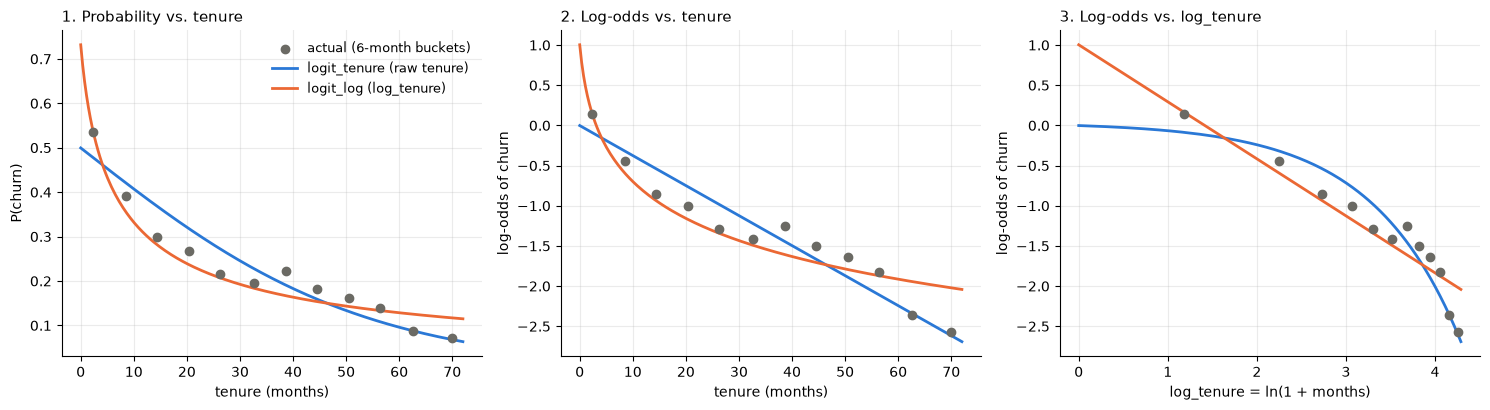

In [8]:
# pre-filled explainer plot: the same data on three scales (consumes train_f, logit_tenure, logit_log)
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#6b6a64"
bins = pd.cut(train_f["tenure"], list(range(0, 72, 6)) + [73], right=False)   # 6-month buckets: 0-5, 6-11, ..., 66-72
pts = train_f.groupby(bins, observed=True).agg(tenure=("tenure", "mean"), p=("churned", "mean"))
pts["log_odds"] = np.log(pts["p"] / (1 - pts["p"]))
pts["log_tenure"] = np.log1p(pts["tenure"])

line = pd.DataFrame({"tenure": np.linspace(0, 72, 200)})
line["log_tenure"] = np.log1p(line["tenure"])
for name, m in (("raw", logit_tenure), ("log", logit_log)):
    line[f"p_{name}"] = m.predict(line)
    line[f"lo_{name}"] = np.log(line[f"p_{name}"] / (1 - line[f"p_{name}"]))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
panels = [("tenure", "p", "p", "1. Probability vs. tenure", "P(churn)"),
          ("tenure", "log_odds", "lo", "2. Log-odds vs. tenure", "log-odds of churn"),
          ("log_tenure", "log_odds", "lo", "3. Log-odds vs. log_tenure", "log-odds of churn")]
for a, (x, y, pre, title, ylab) in zip(ax, panels):
    a.scatter(pts[x], pts[y], s=36, color=GRAY, zorder=3, label="actual (6-month buckets)")
    a.plot(line[x], line[f"{pre}_raw"], color=BLUE, lw=2, label="logit_tenure (raw tenure)")
    a.plot(line[x], line[f"{pre}_log"], color=ORANGE, lw=2, label="logit_log (log_tenure)")
    a.set_title(title, loc="left", fontsize=11)
    a.set_xlabel("log_tenure = ln(1 + months)" if x == "log_tenure" else "tenure (months)")
    a.set_ylabel(ylab)
    a.grid(alpha=0.25)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
ax[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**How to read the three panels:** gray dots are the actual churn rate in each 6-month bucket. The lines are your two models.
1. **Probability scale:** both models are curves here, even the "linear" one, because translating the score back to a probability always bends it. So you can't judge straightness on this panel.
2. **Score scale vs. months:** the blue model has to be a straight line here, and the dots clearly bend (steep, then flat). That's the misfit.
3. **Score scale vs. `log_tenure`:** now the orange model is the straight line, and the dots mostly follow it. The last two dots (60+ months) dip below it: the longest-tenure customers churn even less than the log curve predicts. One more bend that a spline or bins could pick up.

## 2. Fitting a Full Model: the GLM and the Dummy Trap

Covers: *Logistic Regression and the GLM* (book). Logistic regression is a **generalized linear model** with a binomial outcome and a logit link. It is fit by **maximum likelihood**, not least squares: it picks the coefficients that make the observed 0/1 outcomes most probable. Numeric picture: three customers churn, stay, stay, and the model gives them P(churn) = 0.6, 0.2, 0.3. The likelihood is 0.6 × 0.8 × 0.7 = 0.336, and the log-likelihood is ln(0.6) + ln(0.8) + ln(0.7) = −1.09. Statsmodels reports this as `.llf`, and AIC = 2·(number of coefficients) − 2·llf.

Now the data quirk. A customer with no internet has `"No internet service"` in **all six** add-on columns, and `InternetService == "No"` too. Dummy-coding all of them creates seven columns that are identical for the same 1,068 training customers. With identical columns, infinitely many coefficient combinations give the same fit, so there is no single best answer.

(a) Fit `churned ~ tenure + MonthlyCharges + C(Contract, Treatment("Two year")) + InternetService + PaymentMethod + PaperlessBilling + SeniorCitizen` **plus the six raw add-on columns** (`ADDONS`). Use the pre-filled check to say which columns are identical.
(b) Fix it two ways: replace the six columns with `addon_count` (`logit_count`), or with six 0/1 "has it" flags (`logit_flags`). Set `logit_fixed` to the one with the lower AIC; sections 3–4 use it.

**Predict first:** (a) will the raw spec fit fine, fit with huge standard errors, or crash? (b) Which fix gets the lower AIC, the single count or the six flags, and by more or less than 10 points?

*Tools for this question:*
- Formulas take a string, e.g. `"churned ~ tenure + " + " + ".join(ADDONS)`. `C(Contract, Treatment("Two year"))` makes "Two year" the reference level, so the other Contract coefficients compare against it.
- A crash shows up as `numpy.linalg.LinAlgError: Singular matrix`. Wrap the fit in `try: ... except np.linalg.LinAlgError as e: print("failed:", e)` so the notebook keeps running.
- Flags: `train_f[c + "_yes"] = (train_f[c] == "Yes").astype(int)` in a loop over `ADDONS`, for **both** `train_f` and `test_f`.

_Prediction (one line, before running anything):_
* Most likely crash
* I think 6 flags could reach better AIC

In [9]:
# fit the raw spec here (it may fail; catch the error)
base = 'churned ~ tenure + MonthlyCharges + C(Contract, Treatment("Two year")) + InternetService + PaymentMethod + PaperlessBilling + SeniorCitizen'
try:
    raw_spec_model = smf.logit(base + " + " + " + ".join(ADDONS), data=train_f).fit(disp=0)
except np.linalg.LinAlgError as e:
    print("failed:", e)


failed: Singular matrix


In [10]:
# pre-filled: how many training customers have each "no service" level (compare the counts)
print("InternetService == 'No':", (train_f["InternetService"] == "No").sum())
for c in ADDONS:
    print(f"{c:17s} == 'No internet service':", (train_f[c] == "No internet service").sum(),
          "| same customers:", ((train_f[c] == "No internet service") == (train_f["InternetService"] == "No")).all())

InternetService == 'No': 1068
OnlineSecurity    == 'No internet service': 1068 | same customers: True
OnlineBackup      == 'No internet service': 1068 | same customers: True
DeviceProtection  == 'No internet service': 1068 | same customers: True
TechSupport       == 'No internet service': 1068 | same customers: True
StreamingTV       == 'No internet service': 1068 | same customers: True
StreamingMovies   == 'No internet service': 1068 | same customers: True


In [11]:
flag_cols = [c + "_yes" for c in ADDONS]     # ["OnlineSecurity_yes", "OnlineBackup_yes", ...]
" + ".join(flag_cols)                         # "OnlineSecurity_yes + OnlineBackup_yes + ..."


'OnlineSecurity_yes + OnlineBackup_yes + DeviceProtection_yes + TechSupport_yes + StreamingTV_yes + StreamingMovies_yes'

In [12]:
# 0/1 "has it" flags, built the same way in train and test
for c in ADDONS:
    train_f[c + "_yes"] = (train_f[c] == "Yes").astype(int)
    test_f[c + "_yes"] = (test_f[c] == "Yes").astype(int)
flag_cols = [c + "_yes" for c in ADDONS]

logit_count = smf.logit(base + " + addon_count", data=train_f).fit(disp=0)                 # base spec + addon_count
logit_flags = smf.logit(base + " + " + " + ".join(flag_cols), data=train_f).fit(disp=0)   # base spec + six 0/1 add-on flags
logit_fixed = min(logit_count, logit_flags, key=lambda m: m.aic)                          # whichever of the two has the lower AIC


In [13]:
# pre-filled: AIC comparison, the flags model's add-on odds ratios, and the GLM check (consumes logit_count, logit_flags, logit_fixed)
print(f"AIC: addon_count {logit_count.aic:.1f} | six flags {logit_flags.aic:.1f}\n")
flag_terms = [t for t in logit_flags.params.index if any(t.startswith(c) for c in ADDONS)]
print("flags model, odds ratio per add-on:\n", np.exp(logit_flags.params[flag_terms]).round(3), "\n")
glm = smf.glm(logit_fixed.model.formula, data=train_f, family=sm.families.Binomial()).fit()
print("GLM (binomial family) vs. smf.logit, largest coefficient difference:", f"{np.abs(glm.params - logit_fixed.params).max():.1e}")

AIC: addon_count 4195.5 | six flags 4147.5

flags model, odds ratio per add-on:
 OnlineSecurity_yes      0.679
OnlineBackup_yes        0.892
DeviceProtection_yes    1.002
TechSupport_yes         0.721
StreamingTV_yes         1.316
StreamingMovies_yes     1.471
dtype: float64 

GLM (binomial family) vs. smf.logit, largest coefficient difference: 1.7e-14


_What matched, what surprised you, and why (2-3 bullets):_
* **The raw spec crashed, as predicted** (`Singular matrix`). The check shows "No internet service" marks the **same 1,068 customers** in all six add-on columns and in `InternetService == "No"`, so seven dummy columns are identical. The model can't tell which of them deserves the "no internet" effect, so infinitely many coefficient splits fit equally well and there is no unique answer.
* **Six flags beat one count, by a lot:** AIC **4147.5 vs. 4195.5**, a 48-point gap (well past the 10-point bar). A single count assumes every add-on shifts the odds by the same amount, and the flags show that's false.
* **The add-ons even point in opposite directions:** OnlineSecurity (0.68) and TechSupport (0.72) *lower* churn odds, while StreamingTV (1.32) and StreamingMovies (1.47) *raise* them. In a count they cancel out, which is why `addon_count` looked weak. The GLM check (difference 1.7e-14) confirms `smf.logit` is just a binomial GLM.

**Reference card: reading a coefficient, an odds ratio, and its interval**

A coefficient is on the log-odds scale; `exp(coef)` puts it on the odds scale. The two always agree on direction:

| coefficient (log-odds) | odds ratio = exp(coef) | meaning, holding the other features fixed | example (flags model) |
|---|---|---|---|
| **negative** | **below 1** | goes with **lower** churn odds | OnlineSecurity: coef −0.39, OR **0.68** → about 32% lower odds |
| **0** | **1** | no association | DeviceProtection: coef 0.00, OR **1.00** |
| **positive** | **above 1** | goes with **higher** churn odds | StreamingMovies: coef +0.39, OR **1.47** → about 47% higher odds |

- **Percent change in odds** = (OR − 1) × 100. So 0.68 → −32%, 1.47 → +47%. This is a change in *odds*, not in percentage points of probability. Section 3 does that conversion.
- **Odds vs. odds ratio:** the odds are churners per stayer for a customer (always positive). The odds ratio is what a feature *multiplies* those odds by.
- **Check the interval:** if the 95% interval for the OR includes 1, the data can't tell you the direction. OnlineSecurity's interval is about [0.55, 0.84], entirely below 1, so lower churn is clear. DeviceProtection's is about [0.83, 1.22], so it could go either way.
- **Association, not cause:** "OnlineSecurity goes with 32% lower churn odds" is supported. "Selling OnlineSecurity will cut churn odds by 32%" is not: customers who buy it may differ in ways the model doesn't see (R02 Q2).

## 3. Reading the Coefficients: Odds Ratios and Percentage Points

Covers: *Predicted Values, Interpreting Coefficients, Odds Ratios* (book). A coefficient is the change in **log-odds** per unit of the feature, holding the other features fixed. Taking `exp(coef)` turns it into an **odds ratio**: the number the odds get multiplied by. Numeric picture with an odds ratio of 2:

| starting P(churn) | starting odds | odds × 2 | new P(churn) | change |
|---|---|---|---|---|
| 20% | 0.25 | 0.50 | 33% | **+13 points** |
| 50% | 1.00 | 2.00 | 67% | **+17 points** |
| 90% | 9.00 | 18.0 | 95% | **+5 points** |

The odds ratio is the same in every row, but the change in percentage points is not. A retention team thinks in percentage points, so "odds ratio 2" alone doesn't tell them how many extra churners to expect. For a numeric feature the odds ratio is per unit: per month for tenure, so per year it is that number to the 12th power, not times 12.

(a) From `logit_fixed`: `or_m2m`, the odds ratio of month-to-month vs. two-year, and `or_tenure_12`, the odds ratio for 12 more months of tenure.
(b) **By hand:** apply `or_m2m` to two hypothetical customers whose P(churn) on a two-year contract would be 5% and 40%. How many percentage points does switching to month-to-month add for each?

**Predict first:** (a) is the adjusted month-to-month odds ratio below 2, between 2 and 10, or above 10? (b) Does the same odds ratio add more percentage points at a 5% baseline or at a 40% baseline?

*Tools for this question:*
- `np.exp(logit_fixed.params)` → every odds ratio. The month-to-month term is named `'C(Contract, Treatment("Two year"))[T.Month-to-month]'`; copy it from the printed index.
- Odds ↔ probability: odds = p / (1 − p), p = odds / (1 + odds).

_Prediction (one line, before running anything):_ 
* I would imagine that the odds ratio for month-to-month consumers is between 2 and 10.
* I believe 5% baseline could have more room for more percentage points to be added.

In [16]:
logit_fixed.params

Intercept                                              -1.949265
C(Contract, Treatment("Two year"))[T.Month-to-month]    1.379639
C(Contract, Treatment("Two year"))[T.One year]          0.604762
InternetService[T.Fiber optic]                          0.918016
InternetService[T.No]                                  -1.127311
PaymentMethod[T.Credit card (automatic)]               -0.040186
PaymentMethod[T.Electronic check]                       0.391981
PaymentMethod[T.Mailed check]                           0.119752
PaperlessBilling[T.Yes]                                 0.426825
tenure                                                 -0.029176
MonthlyCharges                                         -0.003396
SeniorCitizen                                           0.212751
OnlineSecurity_yes                                     -0.387184
OnlineBackup_yes                                       -0.113906
DeviceProtection_yes                                    0.002186
TechSupport_yes          

In [20]:
or_m2m =  np.exp(logit_fixed.params['C(Contract, Treatment("Two year"))[T.Month-to-month]'])    # odds ratio, month-to-month vs. two-year
or_tenure_12 = np.exp(logit_fixed.params["tenure"])**12     # odds ratio for 12 more months of tenure
pp_low = ((0.05/0.95) * (or_m2m))/(1 + ((0.05/0.95) * (or_m2m))) - 0.05         # by hand: percentage-point change at a 5% baseline
pp_high = ((0.4/0.6) * (or_m2m))/(1 + ((0.4/0.6) * (or_m2m))) - 0.4       # by hand: percentage-point change at a 40% baseline

In [21]:
# pre-filled: odds ratios with 95% intervals (consumes logit_fixed and your four numbers)
ors = pd.DataFrame({"odds_ratio": np.exp(logit_fixed.params), "low": np.exp(logit_fixed.conf_int()[0]), "high": np.exp(logit_fixed.conf_int()[1])})
print(ors.round(3).to_string(), "\n")
print(f"or_m2m {or_m2m:.3f} | or_tenure_12 {or_tenure_12:.3f} | +{pp_low:.3f} at a 5% baseline | +{pp_high:.3f} at a 40% baseline")

                                                      odds_ratio    low   high
Intercept                                                  0.142  0.071  0.285
C(Contract, Treatment("Two year"))[T.Month-to-month]       3.973  2.670  5.914
C(Contract, Treatment("Two year"))[T.One year]             1.831  1.226  2.733
InternetService[T.Fiber optic]                             2.504  1.587  3.953
InternetService[T.No]                                      0.324  0.219  0.479
PaymentMethod[T.Credit card (automatic)]                   0.961  0.735  1.255
PaymentMethod[T.Electronic check]                          1.480  1.187  1.845
PaymentMethod[T.Mailed check]                              1.127  0.864  1.471
PaperlessBilling[T.Yes]                                    1.532  1.287  1.824
tenure                                                     0.971  0.966  0.976
MonthlyCharges                                             0.997  0.984  1.009
SeniorCitizen                                       

_What matched, what surprised you, and why (2-3 bullets):_
* A consumer with a 5% chance to churn on a two-year contract is predicted at 17.3% on month-to-month, a gain of about **12 percentage points**. The 40% consumer goes to 72.6%, a gain of about **33 points**. Same odds ratio (3.97), very different percentage-point effects.
* My original prediction that the odds ratio of month to month consumers being between 2-10 was correct. My thinking process was that odds ratio is the ratio of 2 odds. In our case, its the ratio of odds to churn given m2m contract and odds to churn given 2 year contract. I imagined that the odds to churn given a more flexible contract would be higher so thats why I aimed for 2-10 and didnt expect it to be greater.
* In terms of percentage points being added, I was incorrect. The 5% baseline consumer had a smaller percentage-point gain than the 40% baseline. The odds ratio multiplies both consumers' odds by the same 3.97, but the 5% consumer's odds are tiny (0.053 → 0.209), so even quadrupling them barely moves the probability. Near 50% the S-curve is steepest, so the same multiplier moves the probability the most there. (Their other features are why the baseline is 5% in the first place; the curve is why the gain is small.)

## 4. Assessing the Model: Likelihood-Ratio Test and the Test Set

Covers: *Assessing the Model* (book). In-sample, the check is whether a group of features earns its place. **Deviance** = −2·llf, and the likelihood-ratio statistic is LR = 2·(llf_full − llf_reduced). If the dropped features truly don't matter, LR follows a chi-squared distribution with degrees of freedom = the number of coefficients dropped. Numeric picture: `PaymentMethod` has 4 levels, so it uses 3 coefficients. Dropping it gives 3 degrees of freedom, whose 95th percentile is **7.8**. An LR well above 7.8 means payment method carries signal beyond the other features. This is one test for a whole group, unlike reading three separate p-values.

Out of sample, the check is the scorecard. One property to know: with an intercept, the average predicted probability on the **training** data equals the training churn rate exactly (26.5%). Maximum likelihood forces that, which is part of why logistic probabilities tend to be honest.

(a) **By hand, once:** fit `logit_reduced` = `logit_fixed`'s spec without `PaymentMethod`, then compute `lr_stat` and `lr_p`.
(b) Score the test set: `p_logit` = `logit_fixed`'s P(churn) for `test_f`.

**Predict first:** (a) will `lr_stat` be above or below 7.8? (b) Will logistic beat LDA's 0.793 accuracy, tie (within 1 point), or lose? Will **any** test customer get P(churn) above 90%?

*Tools for this question:*
- `.llf` → log-likelihood. `stats.chi2.sf(x, df)` → P(chi-squared > x), the p-value.
- `logit_fixed.model.formula` → the formula string, so `.replace(" + PaymentMethod", "")` builds the reduced spec.
- `logit_fixed.predict(test_f)` → P(churn) per test row. Gotcha: `test_f` needs the same feature columns (the flags too).

_Prediction (one line, before running anything):_

* I predict that hte lr_stat will be above 7.8.
* I believe that logistic will beat LDA
* I believe that if the training set did not see any 90% churn consumers it will not predict so in the test set.

In [22]:
logit_fixed.model.formula.replace(" + PaymentMethod", "")

'churned ~ tenure + MonthlyCharges + C(Contract, Treatment("Two year")) + InternetService + PaperlessBilling + SeniorCitizen + OnlineSecurity_yes + OnlineBackup_yes + DeviceProtection_yes + TechSupport_yes + StreamingTV_yes + StreamingMovies_yes'

In [26]:
logit_reduced = smf.logit('churned ~ tenure + MonthlyCharges + C(Contract, Treatment("Two year")) + InternetService + PaperlessBilling + SeniorCitizen + OnlineSecurity_yes + OnlineBackup_yes + DeviceProtection_yes + TechSupport_yes + StreamingTV_yes + StreamingMovies_yes', data = train_f).fit()  # logit_fixed's spec without PaymentMethod
lr_stat = 2 * (logit_fixed.llf - logit_reduced.llf)        # 2 * (llf_full - llf_reduced)
lr_p = stats.chi2.sf(lr_stat, 3)           # chi-squared p-value with df = number of coefficients dropped

Optimization terminated successfully.
         Current function value: 0.419073
         Iterations 8


In [27]:
# pre-filled: consumes logit_fixed, logit_reduced, lr_stat, lr_p
print("coefficients dropped:", int(logit_fixed.df_model - logit_reduced.df_model), "(should be 3)")
print(f"LR = {lr_stat:.1f}, p = {lr_p:.2g} | McFadden pseudo-R² = {logit_fixed.prsquared:.3f}")
print(f"train: mean predicted P(churn) {logit_fixed.predict(train_f).mean():.4f} vs. actual churn rate {y_train.mean():.4f}")

coefficients dropped: 3 (should be 3)
LR = 20.6, p = 0.00013 | McFadden pseudo-R² = 0.279
train: mean predicted P(churn) 0.2653 vs. actual churn rate 0.2653


In [28]:
p_logit = logit_fixed.predict(test_f)  # logit_fixed's P(churn) on test_f

In [29]:
# pre-filled: notebook 13's baselines vs. logistic (consumes p_logit)
report(p_nb_lean, y_test, "Naive Bayes, lean")
report(p_lda, y_test, "LDA, 6 numeric")
report(p_logit, y_test, "Logistic")
print("\nLogistic — does 'P = 70%' mean 70%?")
confidence_table(p_logit, y_test)

Naive Bayes, lean            accuracy 0.762 (everyone-stays baseline 0.735) | churners caught 66.0% | customers flagged 682 of 2113
LDA, 6 numeric               accuracy 0.793 (everyone-stays baseline 0.735) | churners caught 51.9% | customers flagged 458 of 2113
Logistic                     accuracy 0.801 (everyone-stays baseline 0.735) | churners caught 53.7% | customers flagged 462 of 2113

Logistic — does 'P = 70%' mean 70%?


,share_of_customers,mean_predicted,actual_churn_rate
band,,,
"(-0.001, 0.1]",0.372,0.038,0.037
"(0.1, 0.5]",0.410,0.275,0.267
"(0.5, 0.9]",0.219,0.644,0.652


_What matched, what surprised you, and why (2-3 bullets):_
* LR stat is well above 7.8 at 20.6 (p = 0.00013), so payment method carries real signal **beyond** the other features (an in-sample check, not a test-set one).
* Logistic's 0.801 vs. LDA's 0.793 is a **0.8-point gap, a tie** by my own within-1-point bucket, so my "beat" prediction was off. The real win is calibration: in the 50–90% band the model's mean prediction is 64.4% and 65.2% actually churned, so its probabilities mean what they say.
* No test customer reached 90%; the max was 84% (training max 84.7%). The training set holds 0/1 outcomes, not probabilities, and even the riskiest group (month-to-month, fiber, tenure ≤ 6, electronic check; 311 customers) churns only **73%** of the time. Maximum likelihood ties predictions to actual churn rates, so the model never has a reason to say 90%.

**Where this leaves the project question:** in one or two sentences, what would you now tell the retention team about *who* churns (in percentage points they can use), and which of the three models' probabilities you'd trust for a budget decision?

* **Who churns:** month-to-month, short-tenure, fiber, electronic-check customers. Month-to-month alone goes with about **+12 percentage points** for a customer who'd be at 5% on a two-year contract and about **+33 points** for one at 40%, an association, not a promise of what changing the contract would do.
* **Which model to trust for a budget:** logistic. Not for accuracy (it ties LDA), but because its probabilities are **calibrated**: when it says ~64%, about 65% churn, so expected-churner counts per dollar can be read straight off it.